In [147]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from ase.io.trajectory import Trajectory
import pandas as pd

In [148]:
Data = {'Temperature':[],'Energy_per_atom':[],'Force_per_atom':[],'Stress_per_atom':[]}
MLP_Data = {'Temperature':[],'Energy_per_atom':[],'Force_per_atom':[],'Stress_per_atom':[]}

In [149]:
for file in os.listdir("/Users/yinziqi/PycharmProjects/MACE/MD_FOLDER/STO/MC_structure/VASP_Traj"):
    if file.split('.')[0] in ['100','300','3000']:
        for atoms in Trajectory(os.path.join("/Users/yinziqi/PycharmProjects/MACE/MD_FOLDER/STO/MC_structure/VASP_Traj",file)):
            Data['Temperature'].append(int(file.split('.')[0]))
            Data['Force_per_atom'].append(np.linalg.norm(atoms.get_forces())/len(atoms))
            Data['Energy_per_atom'].append(np.linalg.norm(atoms.get_potential_energy())/len(atoms))
            Data['Stress_per_atom'].append(np.linalg.norm(atoms.get_stress())/len(atoms))


In [150]:
for atoms in Trajectory('/Users/yinziqi/PycharmProjects/MACE/test_code/HEP_pretrained.traj'):
    MLP_Data['Temperature'].append(300)
    MLP_Data['Force_per_atom'].append(np.linalg.norm(atoms.get_forces())/len(atoms))
    MLP_Data['Energy_per_atom'].append(np.linalg.norm(atoms.get_potential_energy())/len(atoms))
    MLP_Data['Stress_per_atom'].append(np.linalg.norm(atoms.get_stress())/len(atoms))
    

In [159]:
vasp_df = pd.DataFrame(Data)
MLP_df = pd.DataFrame(MLP_Data)
def normalize(df):
    df['Energy_per_atom'] = (df['Energy_per_atom']-df['Energy_per_atom'].min())/(df['Energy_per_atom'].max()-df['Energy_per_atom'].min())
    df['Force_per_atom'] = (df['Force_per_atom']-df['Force_per_atom'].min())/(df['Force_per_atom'].max()-df['Force_per_atom'].min())
    # df['Temperature'] = (df['Temperature']-df['Temperature'].min())/(df['Temperature'].max()-df['Temperature'].min())
    return df
vasp_df = normalize(vasp_df)
MLP_df = normalize(MLP_df)

In [160]:
sample3000 = vasp_df[vasp_df['Temperature'] == 3000]
sample100 = vasp_df[vasp_df['Temperature'] == 100]
sample300 = vasp_df[vasp_df['Temperature'] == 300]
print(sample300)

     Temperature  Energy_per_atom  Force_per_atom  Stress_per_atom
271          300         0.982636        0.102574         0.000038
272          300         0.982542        0.102888         0.000038
273          300         0.982163        0.103718         0.000038
274          300         0.981503        0.105217         0.000038
275          300         0.980572        0.107240         0.000038
..           ...              ...             ...              ...
414          300         0.947496        0.139565         0.000020
415          300         0.947908        0.138854         0.000022
416          300         0.948274        0.138488         0.000023
417          300         0.948598        0.138506         0.000023
418          300         0.948881        0.138932         0.000024

[148 rows x 4 columns]


<Axes: xlabel='Energy_per_atom', ylabel='Force_per_atom'>

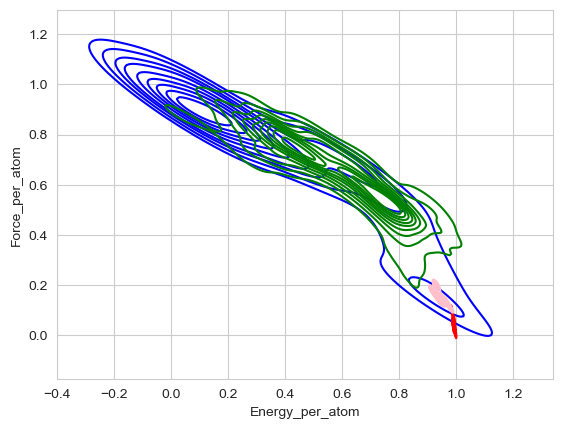

In [162]:
sns.kdeplot(
    data=sample3000, x='Energy_per_atom', y='Force_per_atom', color='blue',
)
sns.kdeplot(
    data=sample100, x='Energy_per_atom', y='Force_per_atom', color='red',
)
sns.kdeplot(
    data=sample300, x='Energy_per_atom', y='Force_per_atom', color='pink',
)
sns.kdeplot(
    data=MLP_df, x='Energy_per_atom', y='Force_per_atom', color='green',
)